In [1]:
!pip install transformers datasets scikit-learn torch pandas numpy tqdm -q

In [ ]:
import pandas as pd
import numpy as np
import re
import os
from collections import Counter
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')


KAGGLE_PATH        = '/kaggle/input/datasets/sooryakiranv2120/sentiment-analysis-1/training.1600000.processed.noemoticon.csv'
KAGGLE_TRAIN_PATH  = '/kaggle/input/datasets/sooryakiranv2120/kaggle-datasets/train.csv'
KAGGLE_MANUAL_PATH = '/kaggle/input/datasets/sooryakiranv2120/kaggle-datasets/testdata.manual.2009.06.14.csv'
GO_TRAIN_PATH      = '/kaggle/input/datasets/sooryakiranv2120/goemotions/goemotions_1.csv'
GO_PATH_2          = '/kaggle/input/datasets/sooryakiranv2120/goemotions/goemotions_2.csv'
GO_PATH_3          = '/kaggle/input/datasets/sooryakiranv2120/goemotions/goemotions_3.csv'
ED_PATH            = '/kaggle/input/datasets/sooryakiranv2120/empathetic-dialogues-raw'
DD_PATH            = '/kaggle/input/datasets/sooryakiranv2120/daily-dialog'
OUTPUT_CSV         = '/kaggle/working/merged_clean_v2.csv'
MODEL_DIR          = '/kaggle/working/sentiment_model'


MODEL_NAME        = 'cardiffnlp/twitter-roberta-base-sentiment-latest'
TARGET_PER_CLASS  = 55_000
RANDOM_STATE      = 42
MAX_LEN           = 128
BATCH_SIZE        = 64
EPOCHS            = 6
LR                = 1e-5

LABEL2ID = {'positive': 0, 'frustrated': 1, 'neutral': 2, 'confused': 3}
ID2LABEL = {v: k for k, v in LABEL2ID.items()}
print(f'Config loaded. Model: {MODEL_NAME}')

Config loaded. Model: cardiffnlp/twitter-roberta-base-sentiment-latest


In [3]:
def clean_text(text: str) -> str:
    """Normalise text: lowercase, strip URLs, mentions, hashtags, special chars."""
    if not isinstance(text, str):
        return ''
    text = text.lower()
    text = re.sub(r'http\S+|www\.\S+', '', text)
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'#\w+', '', text)
    text = re.sub(r'[^\w\s!?.,\'\-]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def is_usable(text: str, min_chars: int = 8) -> bool:
    """Filter out texts that are too short to carry signal."""
    return len(text) >= min_chars

print('Utility functions loaded.')

Utility functions loaded.


In [ ]:
from datasets import load_dataset

S140_COLS = ['sentiment', 'id', 'date', 'query', 'user', 'text']

#  Source 1: Sentiment140 
print('Loading Sentiment140 ...')
kaggle_big = pd.read_csv(
    KAGGLE_PATH, header=None, names=S140_COLS,
    encoding='latin-1', usecols=['sentiment', 'text'], low_memory=False
)
kaggle_big = kaggle_big[kaggle_big['sentiment'] != 'polarity of tweet'].copy()
kaggle_big['sentiment'] = pd.to_numeric(kaggle_big['sentiment'], errors='coerce')
kaggle_big = kaggle_big.dropna(subset=['sentiment'])
kaggle_big['sentiment'] = kaggle_big['sentiment'].astype(int)
kaggle_big['label'] = kaggle_big['sentiment'].map({4: 'positive', 0: 'frustrated'})
kaggle_big = kaggle_big.dropna(subset=['label'])
kaggle_big['text'] = kaggle_big['text'].apply(clean_text)
kaggle_big = kaggle_big[kaggle_big['text'].apply(is_usable)][['text', 'label']].reset_index(drop=True)
print(f'  Sentiment140:\n{kaggle_big["label"].value_counts()}\n')

#  Source 2: Tweet Sentiment Extraction 
print('Loading train.csv ...')
kaggle_train = pd.read_csv(KAGGLE_TRAIN_PATH, encoding='latin-1')
kaggle_train['text'] = kaggle_train['selected_text'].where(
    kaggle_train['selected_text'].notna() &
    (kaggle_train['selected_text'].str.strip() != kaggle_train['text'].str.strip()),
    kaggle_train['text']
)
kaggle_train['label'] = kaggle_train['sentiment'].map(
    {'positive': 'positive', 'negative': 'frustrated', 'neutral': 'neutral'}
)
kaggle_train = kaggle_train.dropna(subset=['label', 'text'])
kaggle_train['text'] = kaggle_train['text'].apply(clean_text)
kaggle_train = kaggle_train[kaggle_train['text'].apply(is_usable)][['text', 'label']].reset_index(drop=True)
print(f'  train.csv:\n{kaggle_train["label"].value_counts()}\n')

#  Source 3: Sentiment140 manual test file  
print('Loading testdata.manual ...')
kaggle_manual = pd.read_csv(
    KAGGLE_MANUAL_PATH, header=None, names=S140_COLS,
    encoding='latin-1', usecols=['sentiment', 'text'], low_memory=False
)
kaggle_manual = kaggle_manual[kaggle_manual['sentiment'] != 'polarity of tweet'].copy()
kaggle_manual['sentiment'] = pd.to_numeric(kaggle_manual['sentiment'], errors='coerce')
kaggle_manual = kaggle_manual.dropna(subset=['sentiment'])
kaggle_manual['sentiment'] = kaggle_manual['sentiment'].astype(int)
kaggle_manual['label'] = kaggle_manual['sentiment'].map({4: 'positive', 2: 'neutral', 0: 'frustrated'})
kaggle_manual = kaggle_manual.dropna(subset=['label'])
kaggle_manual['text'] = kaggle_manual['text'].apply(clean_text)
kaggle_manual = kaggle_manual[kaggle_manual['text'].apply(is_usable)][['text', 'label']].reset_index(drop=True)
print(f'  testdata.manual:\n{kaggle_manual["label"].value_counts()}\n')

#  Source 4: tweet_eval sentiment 
print('Loading tweet_eval (neutral) ...')
te_df = pd.DataFrame(load_dataset("tweet_eval", "sentiment", split="train"))
neutral_tweets = te_df[te_df['label'] == 1][['text']].copy()
neutral_tweets['label'] = 'neutral'
neutral_tweets['text'] = neutral_tweets['text'].apply(clean_text)
neutral_tweets = neutral_tweets[neutral_tweets['text'].apply(is_usable)].reset_index(drop=True)
print(f'  tweet_eval neutral: {len(neutral_tweets)}\n')

#  Source 5: SST-5 
print('Loading SST-5 (neutral) ...')
sst_df = pd.DataFrame(load_dataset("SetFit/sst5", split="train"))
sst_neutral = sst_df[sst_df['label'] == 2][['text']].copy()
sst_neutral['label'] = 'neutral'
sst_neutral['text'] = sst_neutral['text'].apply(clean_text)
sst_neutral = sst_neutral[sst_neutral['text'].apply(is_usable)].reset_index(drop=True)
print(f'  SST-5 neutral: {len(sst_neutral)}\n')

#  Source 6: AG News
print('Loading AG News (neutral) ...')
ag_df = pd.DataFrame(load_dataset("ag_news", split="train"))
ag_df['label'] = 'neutral'
ag_df['text'] = ag_df['text'].apply(clean_text)
ag_neutral = ag_df[ag_df['text'].apply(is_usable)][['text', 'label']]
ag_neutral = ag_neutral.sample(15_000, random_state=RANDOM_STATE).reset_index(drop=True)
print(f'  AG News neutral: {len(ag_neutral)}\n')

#  Source 7: SNLI 
print('Loading SNLI (neutral) ...')
snli_df = pd.DataFrame(load_dataset("snli", split="train"))
snli_neutral = snli_df[snli_df['label'] == 1][['hypothesis']].rename(columns={'hypothesis': 'text'})
snli_neutral['label'] = 'neutral'
snli_neutral['text'] = snli_neutral['text'].apply(clean_text)
snli_neutral = snli_neutral[snli_neutral['text'].apply(is_usable)]
snli_neutral = snli_neutral.sample(15_000, random_state=RANDOM_STATE).reset_index(drop=True)
print(f'  SNLI neutral: {len(snli_neutral)}\n')

#  Combine all Kaggle + external sources 
kaggle_df = pd.concat(
    [kaggle_big, kaggle_train, kaggle_manual, neutral_tweets, sst_neutral,
     ag_neutral, snli_neutral],
    ignore_index=True
)
print(f'All Kaggle sources combined ({len(kaggle_df):,} rows):')
print(kaggle_df['label'].value_counts())

Loading Sentiment140 ...
  Sentiment140:
label
frustrated    793564
positive      245549
Name: count, dtype: int64

Loading train.csv ...
  train.csv:
label
neutral       10962
positive       5149
frustrated     4983
Name: count, dtype: int64

Loading testdata.manual ...
  testdata.manual:
label
positive      198
frustrated    178
neutral       140
Name: count, dtype: int64

Loading tweet_eval (neutral) ...


README.md: 0.00B [00:00, ?B/s]

sentiment/train-00000-of-00001.parquet:   0%|          | 0.00/3.78M [00:00<?, ?B/s]

sentiment/test-00000-of-00001.parquet:   0%|          | 0.00/901k [00:00<?, ?B/s]

sentiment/validation-00000-of-00001.parq(…):   0%|          | 0.00/167k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/45615 [00:00<?, ? examples/s]

... (22 outputs left out)

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/550152 [00:00<?, ? examples/s]

  SNLI neutral: 15000

All Kaggle sources combined (1,113,014 rows):
label
frustrated    798725
positive      250896
neutral        63393
Name: count, dtype: int64


In [ ]:
from datasets import load_dataset
import re

#  GoEmotions emotion -> 4-class mapping 
GO_EMOTION_MAP = {
    
    'admiration': 'positive', 'amusement': 'positive',  'approval':   'positive',
    'caring':     'positive', 'desire':    'positive',  'excitement': 'positive',
    'gratitude':  'positive', 'joy':       'positive',  'love':       'positive',
    'optimism':   'positive', 'pride':     'positive',  'relief':     'positive',
    
    'anger':          'frustrated', 'annoyance':      'frustrated',
    'disappointment': 'frustrated', 'disapproval':    'frustrated',
    'disgust':        'frustrated', 'remorse':        'frustrated',
    'sadness':        'frustrated', 'grief':          'frustrated',
    
    'neutral':     'neutral', 'realization': 'neutral',
    
    'confusion':     'confused', 'curiosity':    'confused',
    'surprise':      'confused', 'nervousness':  'confused',
    'embarrassment': 'confused', 'fear':         'confused',
}

#  GoEmotions
print('Loading GoEmotions ...')
go_raw = pd.concat(
    [pd.read_csv(p) for p in [GO_TRAIN_PATH, GO_PATH_2, GO_PATH_3]],
    ignore_index=True
)
print(f'  Raw shape: {go_raw.shape}')

meta_cols    = ['text', 'id', 'author', 'subreddit', 'link_id',
                'parent_id', 'created_utc', 'rater_id', 'example_very_unclear']
emotion_cols = [c for c in go_raw.columns if c not in meta_cols]

go_agg = go_raw.groupby('text')[emotion_cols].sum().reset_index()
go_agg['dominant_emotion'] = go_agg[emotion_cols].idxmax(axis=1)
go_agg['label']            = go_agg['dominant_emotion'].map(GO_EMOTION_MAP)
go_df = go_agg[['text', 'label']].dropna().reset_index(drop=True)
go_df['text'] = go_df['text'].apply(clean_text)
go_df = go_df[go_df['text'].apply(is_usable)].reset_index(drop=True)
print(f'  After mapping:\n{go_df["label"].value_counts()}\n')

#  EmpatheticDialogues — confused class 
print('Loading EmpatheticDialogues (confused) ...')
CONFUSED_EMOTIONS = {
    'confused', 'anxious', 'apprehensive', 'terrified',
    'surprised', 'devastated', 'anticipating', 'afraid'
}
ed_frames = []
for split in ['train', 'valid', 'test']:
    path = f'{ED_PATH}/{split}.csv'
    try:
        chunk = pd.read_csv(path, on_bad_lines='skip')
        ed_frames.append(chunk)
        print(f'  Loaded {split}.csv: {len(chunk)} rows')
    except Exception as e:
        print(f'  Skipping {split}.csv: {e}')

if ed_frames:
    ed_raw = pd.concat(ed_frames, ignore_index=True)
    ed_raw['utterance_idx'] = pd.to_numeric(ed_raw['utterance_idx'], errors='coerce')
    ed_df = ed_raw[
        (ed_raw['context'].isin(CONFUSED_EMOTIONS)) &
        (ed_raw['utterance_idx'] == 1)
    ][['utterance', 'context']].copy()
    ed_df = ed_df.rename(columns={'utterance': 'text'})
    ed_df['label'] = 'confused'
    ed_df['text']  = ed_df['text'].apply(clean_text)
    ed_df = ed_df[ed_df['text'].apply(is_usable)][['text', 'label']].reset_index(drop=True)
    print(f'  EmpatheticDialogues confused: {len(ed_df)}\n')
else:
    print('  Not found — skipping\n')
    ed_df = pd.DataFrame(columns=['text', 'label'])

#  DailyDialog — neutral only 
print('Loading DailyDialog (neutral only) ...')
try:
    dd_flat    = pd.read_csv(f'{DD_PATH}/daily_dialog_flat.csv')
    dd_neutral = dd_flat[dd_flat['emotion'] == 0][['text']].copy()
    dd_neutral['label'] = 'neutral'
    dd_neutral['text']  = dd_neutral['text'].apply(clean_text)
    dd_neutral = dd_neutral[dd_neutral['text'].apply(is_usable)].reset_index(drop=True)
    print(f'  DailyDialog neutral: {len(dd_neutral)}\n')
except Exception as e:
    print(f'  Failed: {e} — skipping\n')
    dd_neutral = pd.DataFrame(columns=['text', 'label'])

#  CIRCA — confused 
print('Loading CIRCA (confused) ...')
try:
    circa_df      = pd.DataFrame(load_dataset("circa", split="train"))
    circa_confused = circa_df[circa_df['goldstandard1'].isin([2, 3, 4, 5])][['answer-Y']].copy()
    circa_confused = circa_confused.rename(columns={'answer-Y': 'text'})
    circa_confused['label'] = 'confused'
    circa_confused['text']  = circa_confused['text'].apply(clean_text)
    circa_confused = circa_confused[circa_confused['text'].apply(is_usable)]
    circa_confused = circa_confused.drop_duplicates(subset='text').reset_index(drop=True)
    print(f'  CIRCA confused: {len(circa_confused)}\n')
except Exception as e:
    print(f'  Failed: {e} — skipping\n')
    circa_confused = pd.DataFrame(columns=['text', 'label'])

#  CoQA — confused 
print('Loading CoQA (confused) ...')
CONFUSION_KEYWORDS = [
    "what do you mean", "i don't understand", "can you explain",
    "what exactly", "i'm not sure", "i don't know", "could you clarify",
    "what is", "what was", "what were", "what did", "what does",
    "why did", "why was", "why is", "how did", "how does",
    "who is", "who was", "where is", "where was", "when did",
    "which one", "what kind", "what type", "tell me about"
]

try:
    coqa = load_dataset("coqa", split="train")
    coqa_df = pd.DataFrame(coqa)

    coqa_rows = []
    for _, row in coqa_df.iterrows():
        questions = row.get('questions', [])
        answers   = row.get('answers', {})
        ans_texts = answers.get('input_text', []) if isinstance(answers, dict) else []

        for i, q in enumerate(questions):
            q_lower = q.lower()
            
            if any(kw in q_lower for kw in CONFUSION_KEYWORDS):
                coqa_rows.append({'text': q, 'label': 'confused'})
            
            if i < len(ans_texts) and str(ans_texts[i]).lower() in [
                'unknown', "i don't know", 'i dont know', "not known"
            ]:
                coqa_rows.append({'text': ans_texts[i], 'label': 'confused'})

    coqa_confused = pd.DataFrame(coqa_rows)
    coqa_confused['text'] = coqa_confused['text'].apply(clean_text)
    coqa_confused = coqa_confused[
        coqa_confused['text'].apply(is_usable)
    ].drop_duplicates(subset='text').reset_index(drop=True)
    print(f'  CoQA confused rows: {len(coqa_confused):,}\n')

except Exception as e:
    print(f'  CoQA failed: {e} — skipping\n')
    coqa_confused = pd.DataFrame(columns=['text', 'label'])


#  tweet_eval irony — confused  
print('Loading tweet_eval irony (confused) ...')
try:
    irony_df      = pd.DataFrame(load_dataset("tweet_eval", "irony", split="train"))
    irony_confused = irony_df[irony_df['label'] == 1][['text']].copy()
    irony_confused['label'] = 'confused'
    irony_confused['text']  = irony_confused['text'].apply(clean_text)
    irony_confused = irony_confused[irony_confused['text'].apply(is_usable)].reset_index(drop=True)
    print(f'  tweet_eval irony confused: {len(irony_confused)}\n')
except Exception as e:
    print(f'  Failed: {e} — skipping\n')
    irony_confused = pd.DataFrame(columns=['text', 'label'])

#  Multi-NLI — neutral class only 
print('Loading Multi-NLI (neutral) ...')
try:
    mnli_df      = pd.DataFrame(load_dataset("multi_nli", split="train"))
    mnli_neutral = mnli_df[mnli_df['label'] == 1][['hypothesis']].rename(columns={'hypothesis': 'text'})
    mnli_neutral['label'] = 'neutral'
    mnli_neutral['text']  = mnli_neutral['text'].apply(clean_text)
    mnli_neutral = mnli_neutral[mnli_neutral['text'].apply(is_usable)]
    mnli_neutral = mnli_neutral.sample(15_000, random_state=RANDOM_STATE).reset_index(drop=True)
    print(f'  Multi-NLI neutral: {len(mnli_neutral)}\n')
except Exception as e:
    print(f'  Failed: {e} — skipping\n')
    mnli_neutral = pd.DataFrame(columns=['text', 'label'])

#  Combine all GoEmotions + auxiliary sources 
go_df = pd.concat(
    [go_df, ed_df, dd_neutral, circa_confused, coqa_confused, irony_confused, mnli_neutral],
    ignore_index=True
)
print(f'GoEmotions + all auxiliary sources combined:')
print(go_df['label'].value_counts())

Loading GoEmotions ...
  Raw shape: (211225, 37)
  After mapping:
label
positive      22661
neutral       17000
frustrated    11881
confused       5999
Name: count, dtype: int64

Loading EmpatheticDialogues (confused) ...
  Loaded train.csv: 76668 rows
  Loaded valid.csv: 6318 rows
  Loaded test.csv: 5701 rows
  EmpatheticDialogues confused: 5316

Loading DailyDialog (neutral only) ...
  DailyDialog neutral: 11575

Loading CIRCA (confused) ...


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/2.28M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/34268 [00:00<?, ? examples/s]

  CIRCA confused: 5009

Loading CoQA (confused) ...


README.md: 0.00B [00:00, ?B/s]

... (16 outputs left out)

Generating train split:   0%|          | 0/392702 [00:00<?, ? examples/s]

Generating validation_matched split:   0%|          | 0/9815 [00:00<?, ? examples/s]

Generating validation_mismatched split:   0%|          | 0/9832 [00:00<?, ? examples/s]

  Multi-NLI neutral: 15000

GoEmotions + all auxiliary sources combined:
label
confused      44492
neutral       43575
positive      22661
frustrated    11881
Name: count, dtype: int64


In [ ]:
print('Merging all sources ...')

# Remove intra-source contradictions 
for name, source_df in [('Kaggle', kaggle_df), ('GoEmotions', go_df)]:
    counts = source_df.groupby('text')['label'].nunique()
    bad    = counts[counts > 1].index
    source_df.drop(source_df[source_df['text'].isin(bad)].index, inplace=True)
    print(f'  {name}: removed {len(bad)} contradicted texts')

merged = pd.concat([kaggle_df, go_df], ignore_index=True)
print(f'\nCombined shape: {merged.shape}')

before = len(merged)
merged = merged.drop_duplicates(subset=['text', 'label']).reset_index(drop=True)
print(f'After deduplication: {merged.shape}  (removed {before - len(merged)} rows)')

print(f'\nPre-balance distribution:')
print(merged['label'].value_counts())

#  Per-class caps 
confused_count = (merged['label'] == 'confused').sum()
neutral_count  = (merged['label'] == 'neutral').sum()
print(f'\nConfused available: {confused_count:,} | Neutral available: {neutral_count:,}')

per_class_cap = {
    'positive':   55_000,
    'frustrated': 55_000,
    'neutral':    min(neutral_count,  60_000),
    'confused':   confused_count       
}
print(f'Per-class caps: {per_class_cap}')

balanced = (
    merged
    .groupby('label', group_keys=False)
    .apply(lambda x: x.sample(min(len(x), per_class_cap[x.name]), random_state=RANDOM_STATE))
    .reset_index(drop=True)
    .sample(frac=1, random_state=RANDOM_STATE)
)

print(f'\nFinal balanced distribution:')
print(balanced['label'].value_counts())
print(f'\nTotal rows: {len(balanced):,}')

balanced.to_csv(OUTPUT_CSV, index=False)
print(f'Saved to {OUTPUT_CSV}')

Merging all sources ...
  Kaggle: removed 7767 contradicted texts
  GoEmotions: removed 23 contradicted texts

Combined shape: (1214063, 2)
After deduplication: (1189571, 2)  (removed 24492 rows)

Pre-balance distribution:
label
frustrated    785075
positive      260525
neutral        99563
confused       44408
Name: count, dtype: int64

Confused available: 44,408 | Neutral available: 99,563
Per-class caps: {'positive': 55000, 'frustrated': 55000, 'neutral': 60000, 'confused': np.int64(44408)}

Final balanced distribution:
label
neutral       60000
frustrated    55000
positive      55000
confused      44408
Name: count, dtype: int64

Total rows: 214,408
Saved to /kaggle/working/merged_clean_v2.csv


In [7]:
from sklearn.model_selection import train_test_split

df = pd.read_csv(OUTPUT_CSV)

train_df, temp_df = train_test_split(
    df, test_size=0.2, stratify=df['label'], random_state=RANDOM_STATE
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df['label'], random_state=RANDOM_STATE
)

print(f'Train: {len(train_df):,} | Val: {len(val_df):,} | Test: {len(test_df):,}')
print('\nTrain label distribution:')
print(train_df['label'].value_counts())

Train: 171,526 | Val: 21,441 | Test: 21,441

Train label distribution:
label
neutral       48000
frustrated    44000
positive      44000
confused      35526
Name: count, dtype: int64


In [8]:
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class SentimentDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len):
        self.texts     = list(texts)
        self.labels    = [LABEL2ID[l] for l in labels]
        self.tokenizer = tokenizer
        self.max_len   = max_len

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding='max_length',
            max_length=self.max_len,
            return_tensors='pt'
        )
        return {
            'input_ids':      enc['input_ids'].squeeze(0),
            'attention_mask': enc['attention_mask'].squeeze(0),
            'labels':         torch.tensor(self.labels[idx], dtype=torch.long)
        }

train_dataset = SentimentDataset(train_df['text'], train_df['label'], tokenizer, MAX_LEN)
val_dataset   = SentimentDataset(val_df['text'],   val_df['label'],   tokenizer, MAX_LEN)
test_dataset  = SentimentDataset(test_df['text'],  test_df['label'],  tokenizer, MAX_LEN)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=4, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE * 2, shuffle=False,
                          num_workers=4, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE * 2, shuffle=False,
                          num_workers=4, pin_memory=True)

print(f'Train batches: {len(train_loader):,}')
print(f'Val batches:   {len(val_loader):,}')
print(f'Test batches:  {len(test_loader):,}')

config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Train batches: 2,681
Val batches:   168
Test batches:  168


In [9]:
from transformers import AutoModelForSequenceClassification
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device} | GPUs: {torch.cuda.device_count()}')

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(LABEL2ID),
    id2label=ID2LABEL,
    label2id=LABEL2ID,
    ignore_mismatched_sizes=True
).float().to(device)

print(f'GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f}GB')

optimizer = AdamW(model.parameters(), lr=LR, weight_decay=0.01)

total_steps  = len(train_loader) * EPOCHS
warmup_steps = int(0.1 * total_steps)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)

print(f'Parameters: {sum(p.numel() for p in model.parameters()):,}')
print(f'Total steps: {total_steps:,} | Warmup steps: {warmup_steps:,}')

Device: cuda | GPUs: 2


pytorch_model.bin:   0%|          | 0.00/501M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                             | Status     |                                                                                     
--------------------------------+------------+-------------------------------------------------------------------------------------
roberta.pooler.dense.weight     | UNEXPECTED |                                                                                     
roberta.pooler.dense.bias       | UNEXPECTED |                                                                                     
roberta.embeddings.position_ids | UNEXPECTED |                                                                                     
classifier.out_proj.weight      | MISMATCH   | Reinit due to size mismatch ckpt: torch.Size([3, 768]) vs model:torch.Size([4, 768])
classifier.out_proj.bias        | MISMATCH   | Reinit due to size mismatch ckpt: torch.Size([3]) vs model:to

model.safetensors:   0%|          | 0.00/501M [00:00<?, ?B/s]

GPU Memory: 15.6GB
Parameters: 124,648,708
Total steps: 16,086 | Warmup steps: 1,608


In [ ]:
from sklearn.metrics import accuracy_score, f1_score
from sklearn.utils.class_weight import compute_class_weight
from torch.cuda.amp import GradScaler

# Class weights 
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.array(['positive', 'frustrated', 'neutral', 'confused']),
    y=train_df['label'].values
)
class_weights[2] *= 1.5   # neutral  — boost confidence on factual statements
class_weights[3] *= 1.2   # confused — precision was slightly weak
class_weights = np.clip(class_weights, a_min=None, a_max=5.0)

weights_tensor = torch.tensor(class_weights, dtype=torch.float).to(device)
print('Class weights:', dict(zip(['positive', 'frustrated', 'neutral', 'confused'],
                                  class_weights.round(3))))

criterion = torch.nn.CrossEntropyLoss(weight=weights_tensor)
scaler    = GradScaler(enabled=False)   # disabled — twitter-roberta uses FP32

def evaluate(model, loader, device):
    eval_model = model.module if hasattr(model, 'module') else model
    eval_model.eval()
    all_preds, all_labels = [], []
    total_loss = 0.0

    with torch.no_grad():
        for batch in loader:
            input_ids      = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels         = batch['labels'].to(device)
            outputs = eval_model(input_ids=input_ids, attention_mask=attention_mask)
            loss    = criterion(outputs.logits, labels)
            total_loss += loss.item()
            all_preds.extend(outputs.logits.argmax(dim=-1).cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    return (
        total_loss / len(loader),
        accuracy_score(all_labels, all_preds),
        f1_score(all_labels, all_preds, average='macro')
    )

best_val_f1     = 0.0
best_model_path = os.path.join(MODEL_DIR, 'best_model')
os.makedirs(MODEL_DIR, exist_ok=True)

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss = 0.0

    for batch in tqdm(train_loader, desc=f'Epoch {epoch}/{EPOCHS}'):
        optimizer.zero_grad()
        input_ids      = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels         = batch['labels'].to(device)
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        loss    = criterion(outputs.logits, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        train_loss += loss.item()

    avg_train = train_loss / len(train_loader)
    val_loss, val_acc, val_f1 = evaluate(model, val_loader, device)

    print(f'Epoch {epoch}: train_loss={avg_train:.4f}  '
          f'val_loss={val_loss:.4f}  val_acc={val_acc:.4f}  val_macro_f1={val_f1:.4f}')

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        save_model  = model.module if hasattr(model, 'module') else model
        save_model.save_pretrained(best_model_path)
        tokenizer.save_pretrained(best_model_path)
        print(f'  ✓ Best model saved (val_macro_f1={best_val_f1:.4f})')

print('\nTraining complete.')

Class weights: {'positive': np.float64(0.975), 'frustrated': np.float64(0.975), 'neutral': np.float64(1.34), 'confused': np.float64(1.448)}



Epoch 1/6: 100%|██████████| 2681/2681 [57:42<00:00,  1.29s/it]


Epoch 1: train_loss=0.6152  val_loss=0.4548  val_acc=0.8250  val_macro_f1=0.8248


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  ✓ Best model saved (val_macro_f1=0.8248)


Epoch 2/6: 100%|██████████| 2681/2681 [57:49<00:00,  1.29s/it]


... (13 outputs left out)

Epoch 6/6: 100%|██████████| 2681/2681 [57:48<00:00,  1.29s/it]


Epoch 6: train_loss=0.2546  val_loss=0.4416  val_acc=0.8466  val_macro_f1=0.8478


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  ✓ Best model saved (val_macro_f1=0.8478)

Training complete.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Test Accuracy : 0.8468
Test Macro-F1 : 0.8480

Classification Report:
              precision    recall  f1-score   support

    positive       0.82      0.77      0.79      5500
  frustrated       0.81      0.82      0.82      5500
     neutral       0.88      0.88      0.88      6000
    confused       0.88      0.92      0.90      4441

    accuracy                           0.85     21441
   macro avg       0.85      0.85      0.85     21441
weighted avg       0.85      0.85      0.85     21441



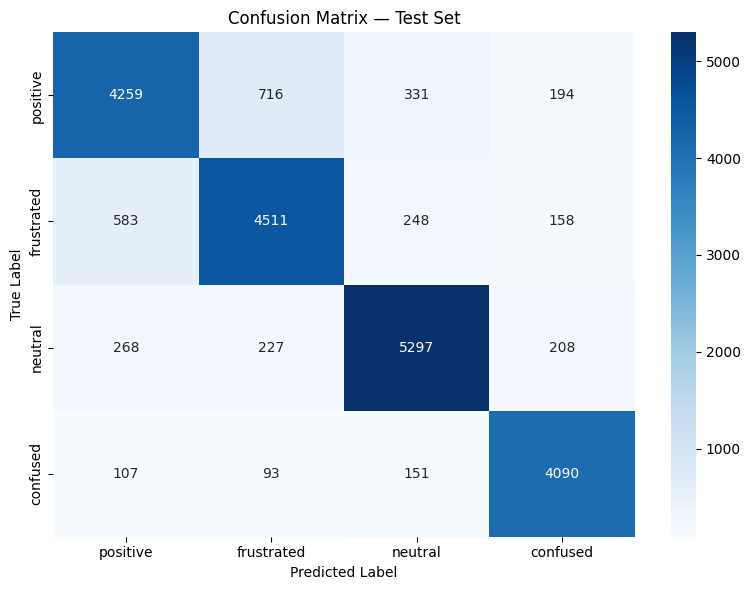

In [11]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import AutoModelForSequenceClassification

best_model = AutoModelForSequenceClassification.from_pretrained(best_model_path).to(device)

_, test_acc, test_f1 = evaluate(best_model, test_loader, device)
print(f'Test Accuracy : {test_acc:.4f}')
print(f'Test Macro-F1 : {test_f1:.4f}\n')

best_model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for batch in test_loader:
        outputs = best_model(
            input_ids=batch['input_ids'].to(device),
            attention_mask=batch['attention_mask'].to(device)
        )
        all_preds.extend(outputs.logits.argmax(-1).cpu().numpy())
        all_labels.extend(batch['labels'].numpy())

label_names = list(LABEL2ID.keys())
print('Classification Report:')
print(classification_report(all_labels, all_preds, target_names=label_names))

# Confusion matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_names, yticklabels=label_names)
plt.title('Confusion Matrix — Test Set')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.savefig('/kaggle/working/confusion_matrix.png', dpi=150)
plt.show()

In [12]:
from transformers import pipeline

classifier = pipeline(
    'text-classification',
    model=best_model_path,
    tokenizer=best_model_path,
    device=0 if torch.cuda.is_available() else -1,
    return_all_scores=True
)

def predict(text: str):
    cleaned = clean_text(text)
    results = classifier(cleaned)
    if isinstance(results[0], list):
        results = results[0]
    results = sorted(results, key=lambda x: x['score'], reverse=True)
    print(f'Input : {text!r}')
    for r in results:
        print(f'  {r["label"]:12s}  {r["score"]:.4f}')
    print()

predict('I absolutely love this, it made my day!')
predict('This is so frustrating, nothing works the way it should.')
predict('The meeting is scheduled for Tuesday.')
predict('Wait, I am not sure I understand what you mean?')

predict("I appreciate the update, but this really set me back more than you think.")
predict("Thanks for the help earlier, though I’m still stuck and feeling a bit overwhelmed.")
predict("I understand the reasoning, but the whole situation is starting to wear me down.")

predict("I’m following what you’re saying… I think.")
predict("Right, okay… so what exactly am I supposed to do next.")
predict("I get the general idea, but something isn’t clicking yet.")

predict("I guess that works, though it wasn’t what I expected.")
predict("It’s fine. Not great, not terrible. Just fine.")
predict("I’ll go along with it, but I’m not sure how I feel about it yet.")

predict("I’ve tried this three times now and it still isn’t behaving the way it should.")
predict("I’m doing everything right, so I don’t understand why this keeps happening.")
predict("This is taking much longer than it should, and I’m running out of patience.")

predict("I’m trying to follow, but the more I read, the less sense it makes.")
predict("I thought I understood this, but now I’m completely lost again.")
predict("I’m not sure whether I’m missing something or if the instructions are unclear.")

predict("That actually turned out better than I expected.")
predict("I wasn’t sure at first, but I’m pleasantly surprised.")
predict("This is starting to make sense now, which is nice.")

predict("I’m glad we made progress, but I’m still worried we’re behind schedule.")
predict("I appreciate the explanation, though I’m still not fully confident I understand.")
predict("I’m excited to try this, even if I’m a bit nervous about messing it up.")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Input : 'I absolutely love this, it made my day!'
  positive      0.9954

Input : 'This is so frustrating, nothing works the way it should.'
  frustrated    0.9645

Input : 'The meeting is scheduled for Tuesday.'
  neutral       0.9468

Input : 'Wait, I am not sure I understand what you mean?'
  confused      0.9046

Input : 'I appreciate the update, but this really set me back more than you think.'
  neutral       0.9307

Input : 'Thanks for the help earlier, though I’m still stuck and feeling a bit overwhelmed.'
  positive      0.4818

Input : 'I understand the reasoning, but the whole situation is starting to wear me down.'
  neutral       0.5760

Input : 'I’m following what you’re saying… I think.'
  positive      0.6099

Input : 'Right, okay… so what exactly am I supposed to do next.'
  confused      0.8622

Input : 'I get the general idea, but something isn’t clicking yet.'
  neutral       0.4905

Input : 'I guess that works, though it wasn’t what I expected.'
  confused      0.7